In [28]:
import os
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, 
    recall_score, f1_score, matthews_corrcoef
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
# 1. Ensure the model/ target directory exists
os.makedirs('model', exist_ok=True)

In [30]:
# 2. Load the training dataset
try:
    df = pd.read_csv('train.csv')
    print(f"Loaded 'train.csv' successfully with shape {df.shape}.\n")
except FileNotFoundError:
    print("Error: 'train.csv' not found. Please put this script in the same folder as your dataset file.")
    exit()

Loaded 'train.csv' successfully with shape (2000, 21).



In [31]:
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [32]:
df.columns

Index(['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g',
       'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height',
       'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi', 'price_range'],
      dtype='str')

In [33]:
# Map the price ranges to text labels for clearer visualization formatting
price_labels = {0: 'Low Cost', 1: 'Medium Cost', 2: 'High Cost', 3: 'Very High Cost'}
df_viz = df.copy()
df_viz['price_label'] = df_viz['price_range'].map(price_labels)
order = ['Low Cost', 'Medium Cost', 'High Cost', 'Very High Cost']

# Set the aesthetics baseline
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 11})

**GRAPH 1: Correlation Heatmap (Feature-to-Feature & Feature-to-Output)**

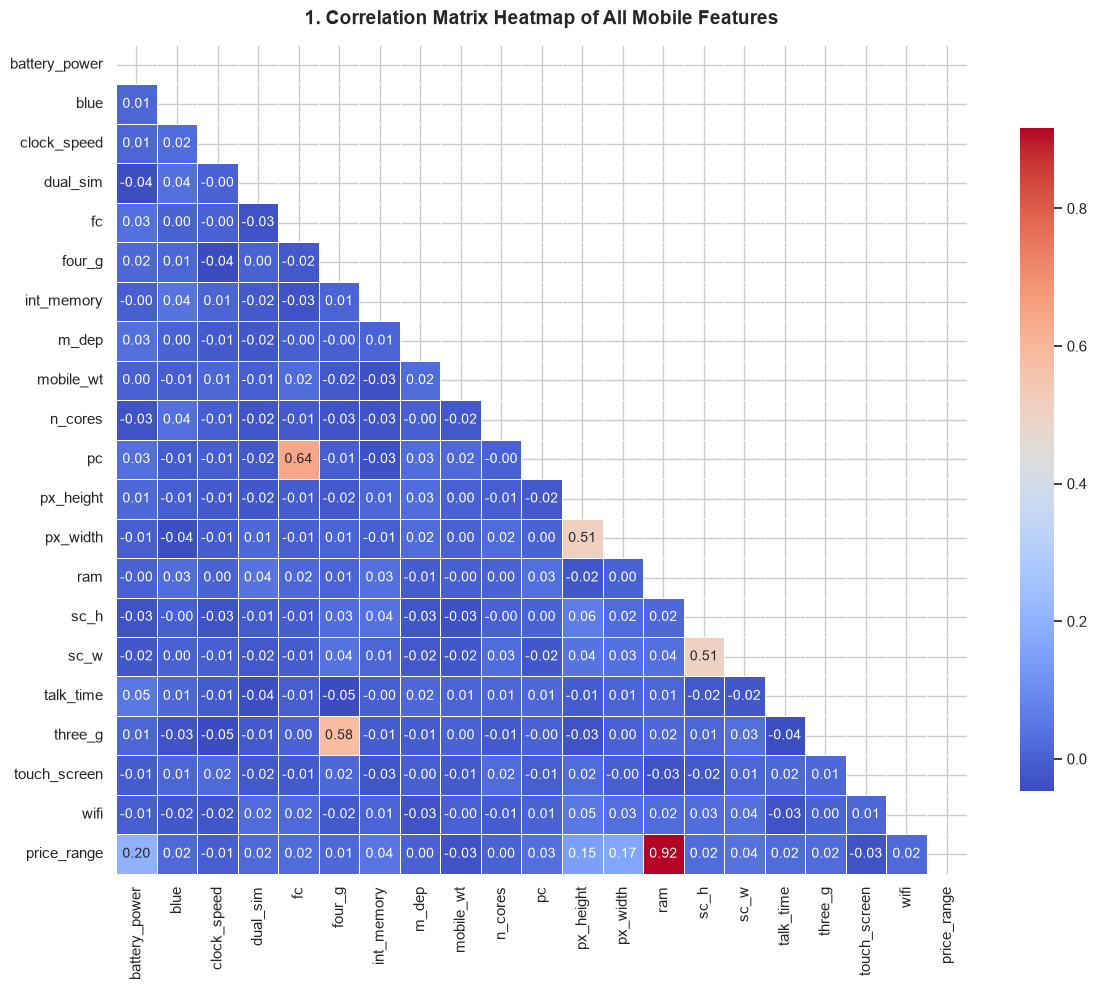

In [34]:
plt.figure(figsize=(12, 10))
# Calculate Pearson correlation matrix across all numeric features
corr_matrix = df.corr()

# Generate a mask for the upper triangle to make the matrix cleaner
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap='coolwarm', 
    annot=True, 
    fmt=".2f", 
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title('1. Correlation Matrix Heatmap of All Mobile Features', fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()

1. *Price Range* has *very high correlation* with *RAM* as correlation score in 0.92. This indicates an extremely strong, linear positive relationship.

2. battery_power (0.20), px_width (0.17), and px_height (0.15) have mild positive correlations.

3. Features like clock_speed (-0.01), mobile_wt (-0.03), and wifi (0.02) have scores hovering near zero, this means they have minimal linear influence on price classification.

4. Primary and Front Cameras: pc (Primary Camera) and fc (Front Camera) have a strong correlation of 0.64. Phones built with high-end rear cameras generally feature upgraded front sensors as well.

5. Network Capabilities: three_g and four_g intersect at 0.58. A 4G phone almost always includes 3G network backwards-compatibility.

6. Screen Dimensions: px_width and px_height intersect at 0.51, while screen dimensions sc_h and sc_w intersect at 0.51.

**GRAPH 2: Boxplot (Primary Feature to Output Relationship)**

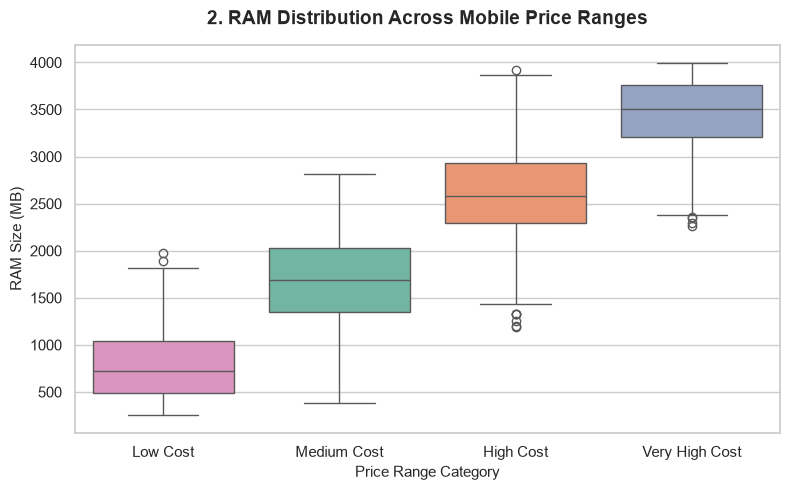

In [35]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_viz, 
    x='price_label', 
    y='ram', 
    order=order, 
    palette='Set2',
    hue='price_label',
    legend=False
)
plt.title('2. RAM Distribution Across Mobile Price Ranges', fontsize=14, weight='bold', pad=15)
plt.xlabel('Price Range Category')
plt.ylabel('RAM Size (MB)')
plt.tight_layout()
plt.show()

**GRAPH 3: Scatter Plot with Hue (Interaction of Multiple Features on Output)**

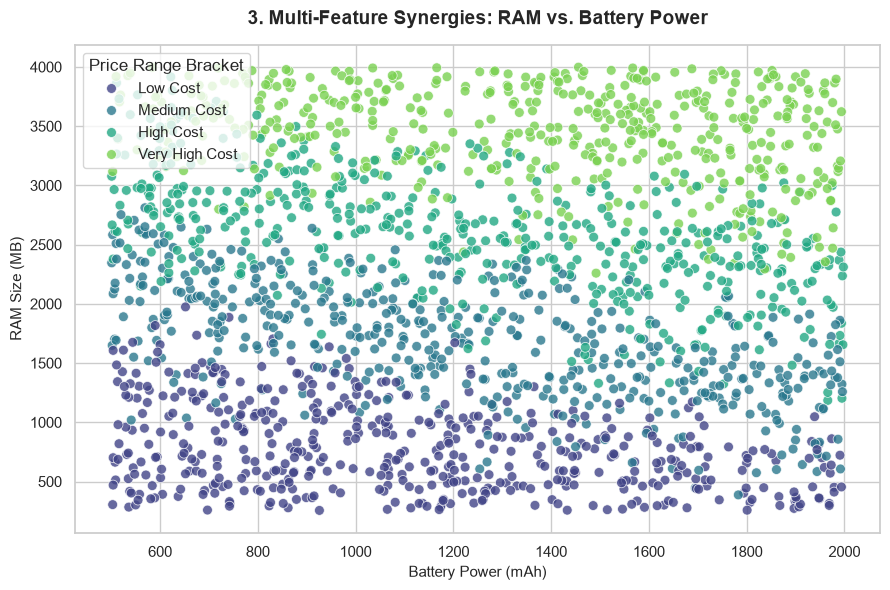

In [36]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_viz, 
    x='battery_power', 
    y='ram', 
    hue='price_label', 
    hue_order=order,
    palette='viridis', 
    alpha=0.8,
    edgecolor='w',
    s=50
)
plt.title('3. Multi-Feature Synergies: RAM vs. Battery Power', fontsize=14, weight='bold', pad=15)
plt.xlabel('Battery Power (mAh)')
plt.ylabel('RAM Size (MB)')
plt.legend(title='Price Range Bracket', loc='upper left')
plt.tight_layout()
plt.show()

From the above plot we can see that RAM and battery power together drive the price range of a mobile phone. As you move along the diagonal, with both RAM and battery power increasing, the price of a mobile phone also increases.

In [37]:
# Separate features from target
X_raw = df.drop(columns=['price_range'])
y = df['price_range']

In [38]:
# Stratified Split (80% Train, 20% Hold-out Validation)
# Seed 42 guarantees deterministic evaluation bounds across all runs.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)


In [39]:
# Export the raw, untouched test data slice for the Streamlit file uploader component
test_df_export = X_test_raw.copy()
test_df_export['price_range'] = y_test
test_df_export.to_csv('test_data.csv', index=False)
print("Holdout validation set exported directly to 'test_data.csv'")

Holdout validation set exported directly to 'test_data.csv'


**FEATURE ENGINEERING & REDUNDANCY PRUNING**

In [40]:
def dynamic_feature_pipeline(data_frame):
    df_out = data_frame.copy()
    
    # Synergy Feature: Linear models struggle with multi-feature diagonal boundaries as seen in case of the combined effect of RAM and Battery Power
    # on mobile phone price in the plot we seen previously.
    # Multiplying RAM and Battery combines them into a clear linear feature.
    df_out['ram_battery_interaction'] = df_out['ram'] * df_out['battery_power']
    
    # Consolidation Feature: Merges highly correlated features (pc & fc correlation: 0.64)
    # to protect Naive Bayes and Logistic Regression from redundant noise. 
    # Naive Bayes works well when the features are independent, so combining 
    # features with high correlation helps to generate independent features.
    # Similarly, Logistic regression works well when it doesn't have to fit on features which create redundant noise, which are the features having little effect
    # on the linear decision boundary.
    df_out['total_megapixels'] = df_out['pc'] + df_out['fc']
    
    # Feature Selection: Dropping redundant cameras AND verified noise columns
    # (clock_speed: -0.01, mobile_wt: -0.03, wifi: 0.02) to optimize distance calculations.
    noise_and_redundant_cols = ['fc', 'pc', 'clock_speed', 'mobile_wt', 'wifi']
    df_out = df_out.drop(columns=[col for col in noise_and_redundant_cols if col in df_out.columns])
    
    return df_out

In [41]:
# Execute data transformations
X_train_ready = dynamic_feature_pipeline(X_train_raw)
X_test_ready = dynamic_feature_pipeline(X_test_raw)

In [42]:
# Uniform scaling to normalize coordinate grids across distance and margin models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_ready)
X_test_scaled = scaler.transform(X_test_ready)

In [43]:
# Serialize structural preprocessing scaler artifact
joblib.dump(scaler, 'model/scaler.joblib')
print("Preprocessing scaler saved: 'model/scaler.joblib'\n")

Preprocessing scaler saved: 'model/scaler.joblib'



In [44]:
# Storage list for compiling final model benchmarks
performance_registry = []

**INDIVIDUAL MODEL PIPELINES**


**MODEL 1: LOGISTIC REGRESSION**

PARAM SELECTION RATIONALE
- max_iter= Have enough iterations that guarantees gradient descent finds the global minimum.
- random_state=42: Forces deterministic calculations inside the solver.

In [45]:
print("Processing Model 1/5: Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
joblib.dump(lr_model, 'model/Logistic_Regression_model.joblib')
print("Saved Logistic Regression: model/Logistic_Regression_model.joblib")

# Track performance
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)

performance_registry.append({
    "Model": "Logistic Regression",
    "Acc": accuracy_score(y_test, y_pred_lr),
    "AUC": roc_auc_score(y_test, y_prob_lr, multi_class='ovr', average='macro'),
    "Prec": precision_score(y_test, y_pred_lr, average='macro', zero_division=0),
    "Rec": recall_score(y_test, y_pred_lr, average='macro', zero_division=0),
    "F1": f1_score(y_test, y_pred_lr, average='macro', zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_lr)
})

Processing Model 1/5: Logistic Regression...
Saved Logistic Regression: model/Logistic_Regression_model.joblib


**MODEL 2: DECISION TREE CLASSIFIER - TUNED VIA GRIDSEARCHCV**

PARAM SELECTION RATIONALE
- criterion=['gini', 'entropy']: Evaluates whether Gini Impurity or Information Gain 
  calculates cleaner feature splits for the mobile pricing boundaries.
- max_depth=[4, 6, 8, 10]: Restricts the vertical growth of branches to prevent the tree 
  from creating overly specific rules for minor data fluctuations.
- min_samples_leaf=[5, 10, 20]: Forces leaf nodes to contain a minimum number of samples, 
  ensuring any structural rule discovered by the tree represents a statistically 
  significant pocket of mobile devices rather than localized noise.
- cv=5: Protects the tuning pipeline against validation split bias.

In [46]:
from sklearn.model_selection import GridSearchCV

print("Processing Model 2/5: Decision Tree (Tuning via GridSearchCV)...")

# Initialize baseline estimator and grid parameters
base_dt = DecisionTreeClassifier(random_state=42)
dt_param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [4, 6, 8, 10],
    'min_samples_leaf': [5, 10, 20]
}

# Run the parameter tuning grid search
dt_grid_search = GridSearchCV(estimator=base_dt, param_grid=dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid_search.fit(X_train_scaled, y_train)

# Extract optimized metrics parameters
best_dt_params = dt_grid_search.best_params_
print(f"Decision Tree Optimization complete! Best Parameters: {best_dt_params}")

# Capture the optimal model configurations
dt_model = dt_grid_search.best_estimator_

# Export the final optimized model binary
joblib.dump(dt_model, 'model/Decision_Tree_model.joblib')
print("Saved optimized serialized Decision Tree classifier pipeline: model/Decision_Tree_model.joblib")

# Predict and compute test performance
y_pred_dt = dt_model.predict(X_test_scaled)
y_prob_dt = dt_model.predict_proba(X_test_scaled)

performance_registry.append({
    "Model": "Decision Tree",
    "Acc": accuracy_score(y_test, y_pred_dt),
    "AUC": roc_auc_score(y_test, y_prob_dt, multi_class='ovr', average='macro'),
    "Prec": precision_score(y_test, y_pred_dt, average='macro', zero_division=0),
    "Rec": recall_score(y_test, y_pred_dt, average='macro', zero_division=0),
    "F1": f1_score(y_test, y_pred_dt, average='macro', zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_dt)
})


Processing Model 2/5: Decision Tree (Tuning via GridSearchCV)...
Decision Tree Optimization complete! Best Parameters: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 5}
Saved optimized serialized Decision Tree classifier pipeline: model/Decision_Tree_model.joblib


**MODEL 3: K-NEAREST NEIGHBORS (KNN) - TUNED VIA GRIDSEARCHCV**

PARAM SELECTION RATIONALE
- GridSearchCV(..., cv=5): Employs 5-fold cross-validation to protect the neighbor 
  evaluations from localized dataset biases.
- param_grid: Searches over n_neighbors [3, 5, 7, 9, 11] to locate the exact neighborhood depth.
- weights=['uniform', 'distance']: Evaluates whether giving closer neighbors higher voting weight 
  outperforms standard uniform assignments.
- metrics=['euclidean', 'manhattan']: Compares straight-line vs absolute coordinate grid distances 
  to neutralize high-dimensional coordinate noise (Curse of Dimensionality).

In [47]:
from sklearn.model_selection import GridSearchCV

print("Processing Model 3/5: K-Nearest Neighbors (Tuning via GridSearchCV)...")

# Initialize baseline estimator and grid parameters
base_knn = KNeighborsClassifier()
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Run the parameter tuning grid search
knn_grid_search = GridSearchCV(estimator=base_knn, param_grid=knn_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
knn_grid_search.fit(X_train_scaled, y_train)

# Extract optimized metrics parameters
best_knn_params = knn_grid_search.best_params_
print(f"KNN Optimization complete! Best Parameters: {best_knn_params}")

# Capture the optimal model configurations
knn_model = knn_grid_search.best_estimator_

# Export the final optimized model binary
joblib.dump(knn_model, 'model/KNN_model.joblib')
print("Saved optimized serialized KNN classifier pipeline: model/KNN_model.joblib")

# Predict and compute test performance
y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)

performance_registry.append({
    "Model": "K-Nearest Neighbors",
    "Acc": accuracy_score(y_test, y_pred_knn),
    "AUC": roc_auc_score(y_test, y_prob_knn, multi_class='ovr', average='macro'),
    "Prec": precision_score(y_test, y_pred_knn, average='macro', zero_division=0),
    "Rec": recall_score(y_test, y_pred_knn, average='macro', zero_division=0),
    "F1": f1_score(y_test, y_pred_knn, average='macro', zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_knn)
})


Processing Model 3/5: K-Nearest Neighbors (Tuning via GridSearchCV)...
KNN Optimization complete! Best Parameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Saved optimized serialized KNN classifier pipeline: model/KNN_model.joblib


**MODEL 4: GAUSSIAN NAIVE BAYES**

PARAM SELECTION RATIONALE
- var_smoothing=1e-09: Adds a tiny portion of the largest feature variance to 
  all variances. This acts as a stabilizer, preventing calculation crashes or 
  zero-probability traps on strict edge entries.

In [48]:
print("Processing Model 4/5: Gaussian Naive Bayes...")
nb_model = GaussianNB(var_smoothing=1e-09)
nb_model.fit(X_train_scaled, y_train)
joblib.dump(nb_model, 'model/Naive_Bayes_model.joblib')
print("Saved Gaussian Naive Bayes Model: model/Naive_Bayes_model.joblib")


y_pred_nb = nb_model.predict(X_test_scaled)
y_prob_nb = nb_model.predict_proba(X_test_scaled)

performance_registry.append({
    "Model": "Gaussian Naive Bayes",
    "Acc": accuracy_score(y_test, y_pred_nb),
    "AUC": roc_auc_score(y_test, y_prob_nb, multi_class='ovr', average='macro'),
    "Prec": precision_score(y_test, y_pred_nb, average='macro', zero_division=0),
    "Rec": recall_score(y_test, y_pred_nb, average='macro', zero_division=0),
    "F1": f1_score(y_test, y_pred_nb, average='macro', zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_nb)
})

Processing Model 4/5: Gaussian Naive Bayes...
Saved Gaussian Naive Bayes Model: model/Naive_Bayes_model.joblib


**MODEL 5: SUPPORT VECTOR MACHINE (SVM) - WITH HYPERPARAMETER GRID SEARCH**

PARAM SELECTION RATIONALE
- kernel='rbf': Leverages the Radial Basis Function kernel to project specifications 
  into a high-dimensional space for non-linear boundaries.
- GridSearchCV(..., param_grid={'C': [0.1, 1, 10, 100]}, cv=5): Performs 5-fold cross-validation
  to find the best cost parameter C. A lower C yields a softer, wider margin (high bias), 
  while a higher C targets zero training errors (high variance).
- CalibratedClassifierCV(..., ensemble=False): Applied to the dynamically discovered 
  optimal SVM classifier to pull probability metrics for the multi-class AUC evaluation.

In [49]:
from sklearn.model_selection import GridSearchCV

print("Processing Model 5/5: Support Vector Machine (Tuning via GridSearchCV)...")

# Define the baseline model and the parameter grid space
base_svm = SVC(kernel='rbf', random_state=42)
param_grid = {'C': [0.1, 1, 10, 100]}

# Execute grid search on the scaled training dataset
svm_grid_search = GridSearchCV(estimator=base_svm, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid_search.fit(X_train_scaled, y_train)

# Extract the best tuned estimator parameters
best_c_val = svm_grid_search.best_params_['C']
print(f"SVM Optimization complete! Optimal hyperparameter identified: C = {best_c_val}")

# Wrap the optimized model inside the probability calibrator for safe deployment inference
svm_model = CalibratedClassifierCV(svm_grid_search.best_estimator_, ensemble=False)
svm_model.fit(X_train_scaled, y_train)

# Export the final optimized model binary
joblib.dump(svm_model, 'model/SVM_model.joblib')
print("Saved optimized serialized SVM classifier pipeline: model/SVM_model.joblib")

# Predict and compute test performance
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)

performance_registry.append({
    "Model": "Support Vector Machine",
    "Acc": accuracy_score(y_test, y_pred_svm),
    "AUC": roc_auc_score(y_test, y_prob_svm, multi_class='ovr', average='macro'),
    "Prec": precision_score(y_test, y_pred_svm, average='macro', zero_division=0),
    "Rec": recall_score(y_test, y_pred_svm, average='macro', zero_division=0),
    "F1": f1_score(y_test, y_pred_svm, average='macro', zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred_svm)
})


Processing Model 5/5: Support Vector Machine (Tuning via GridSearchCV)...
SVM Optimization complete! Optimal hyperparameter identified: C = 1
Saved optimized serialized SVM classifier pipeline: model/SVM_model.joblib


In [50]:
performance_registry

[{'Model': 'Logistic Regression',
  'Acc': 0.9625,
  'AUC': 0.9982083333333334,
  'Prec': 0.9623136983566304,
  'Rec': 0.9625,
  'F1': 0.962347175991131,
  'MCC': 0.9500395858074635},
 {'Model': 'Decision Tree',
  'Acc': 0.8825,
  'AUC': 0.9556625000000001,
  'Prec': 0.8819848519830952,
  'Rec': 0.8825,
  'F1': 0.8818082159386507,
  'MCC': 0.843607550354708},
 {'Model': 'K-Nearest Neighbors',
  'Acc': 0.7725,
  'AUC': 0.9294166666666668,
  'Prec': 0.7753537144494591,
  'Rec': 0.7725,
  'F1': 0.7721691515876096,
  'MCC': 0.6976673742582566},
 {'Model': 'Gaussian Naive Bayes',
  'Acc': 0.8375,
  'AUC': 0.9713666666666667,
  'Prec': 0.8406530000042405,
  'Rec': 0.8375,
  'F1': 0.8381135345930552,
  'MCC': 0.7839672965618345},
 {'Model': 'Support Vector Machine',
  'Acc': 0.9075,
  'AUC': 0.9629249999999999,
  'Prec': 0.90685533723651,
  'Rec': 0.9075,
  'F1': 0.9069858248741062,
  'MCC': 0.8767908875086634}]